# Regression 2.1 Goal difference

**Scope:** Predict goal difference (Team A goals minus Team B goals) using 104 match records and eight explanatory variables. All variables use information available before the match.

**Explanatory variables:**

1. Elo rating difference, divided by 100.
2. Win-rate difference.
3. Draw-rate difference.
4. Rest-day difference.
5. Home advantage.
6. Previous World Cup experience difference.
7. Head-to-head balance.
8. Competitive-match share difference.


In [1]:
from pathlib import Path
import os
import subprocess
import sys

# Colab downloads the public repository automatically. Local use finds your checkout.
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'Data').is_dir()), None)
if root is None:
    root = Path('/content/data-foundation-assessment') if Path('/content').exists() else Path.cwd() / 'data-foundation-assessment'
    if not (root / '.git').exists():
        subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/KushalRaut/data-foundation-assessment.git', str(root)], check=True)
os.chdir(root)
# Colab may preload NumPy. Keep compatible installed versions instead of replacing it.
import importlib.util
from importlib.metadata import version
in_colab = importlib.util.find_spec('google.colab') is not None
if in_colab:
    packages = ['numpy>=1.26,<3', 'pandas>=2.2,<3', 'scipy>=1.12,<2',
                'statsmodels>=0.14,<0.16', 'matplotlib>=3.8,<4', 'scikit-learn>=1.4,<2']
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--disable-pip-version-check', *packages], check=True)
else:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--disable-pip-version-check', '-r', str(root / 'Regression_2.1/requirements.txt')], check=True)
print('Package versions:', {p: version(p) for p in ['numpy', 'pandas', 'scipy', 'statsmodels', 'matplotlib', 'scikit-learn']})
print('Setup complete. The shared datasets are in Data/.')


Setup complete. The shared datasets are in Data/.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: /Users/kushalraut/Downloads/defense/data-foundation-assessment/.venv/bin/python -m pip install --upgrade pip


## 1. Imports and paths

We use the same eight predictors for all full models. IDs and match dates are metadata, not predictors.

In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

MODEL = "2.1"
FEATURES = [
    "elo_difference",
    "win_rate_difference",
    "draw_rate_difference",
    "rest_difference",
    "home_advantage",
    "world_cup_experience_difference",
    "head_to_head_balance",
    "competitive_share_difference",
]
TARGET = "goal_difference"
# Works in a script, a local notebook, or a Colab clone of the repository.
start = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
ROOT = next(p for p in [start, *start.parents] if (p / "Data").is_dir())
OUT = ROOT / f"Regression_{MODEL}" / "outputs"
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {
        "font.size": 10,
        "figure.dpi": 120,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)



## 2. Load and validate the data

Check the required row count, unique IDs and actual outcomes before fitting. Stop if a check fails; do not silently delete rows.

In [3]:
suffix = MODEL.replace(".", "_")
dataset = pd.read_csv(ROOT / "Data" / f"regression_{suffix}.csv")
matches = pd.read_csv(ROOT / "Data/matches_fifa.csv", parse_dates=["date"])
row_id = "match_id" if MODEL == "2.1" else "row_id"
expected_rows = 104 if MODEL == "2.1" else 208
assert dataset.shape == (expected_rows, 10)
assert dataset.columns.tolist() == [row_id, *FEATURES, TARGET]
assert dataset[row_id].is_unique and not dataset.isna().any().any()
assert np.isfinite(dataset[FEATURES + [TARGET]].to_numpy()).all()
assert matches.match_id.is_unique and len(matches) == 104
if MODEL == "2.1":
    df = dataset.merge(matches, on="match_id", validate="one_to_one")
    assert (df[TARGET] == df.goals_a - df.goals_b).all()
    df = df.rename(columns={"team_a": "team", "team_b": "opponent"})
else:
    meta = pd.read_csv(ROOT / "Data/team_match_metadata.csv", parse_dates=["date"])
    df = dataset.merge(meta, on="row_id", validate="one_to_one")
    assert len(df) == 208 and (df.groupby("match_id").size() == 2).all()
    assert (df.groupby("match_id").date.nunique() == 1).all()
    for match in matches.itertuples():
        pair = df[df.match_id == match.match_id].set_index("team")
        assert pair.loc[match.team_a, TARGET] == match.goals_a
        assert pair.loc[match.team_b, TARGET] == match.goals_b
        assert (pair.date == match.date).all()
assert not df.date.isna().any()
df = df.sort_values(["date", row_id]).reset_index(drop=True)
print(f"Regression {MODEL}: {len(df)} rows; exactly {len(FEATURES)} predictors.")



Regression 2.1: 104 rows; exactly 8 predictors.


## 3. Split by whole match dates

Use earlier matches for training and later matches for testing. Whole dates stay together. For team goals, both rows of each match also stay together.

In [4]:
# Preserve the date-based 80% rule from the team's Regression 2.2 contribution.
match_dates = (
    df[["match_id", "date"]].drop_duplicates().sort_values(["date", "match_id"])
)
counts = match_dates.groupby("date").size().cumsum()
cutoff = (counts - int(len(match_dates) * 0.8)).abs().idxmin()
train = df[df.date <= cutoff].copy()
test = df[df.date > cutoff].copy()
assert train.date.max() < test.date.min()
assert set(train.match_id).isdisjoint(test.match_id)
split = match_dates.copy()
split["split"] = np.where(split.date <= cutoff, "Training", "Test")
split.to_csv(OUT / "split.csv", index=False)
print(
    f"Training: {train.match_id.nunique()} matches / {len(train)} rows through {cutoff.date()}"
)
print(
    f"Test: {test.match_id.nunique()} matches / {len(test)} rows from {test.date.min().date()}"
)
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]



Training: 82 matches / 82 rows through 2026-07-01
Test: 22 matches / 22 rows from 2026-07-02


## 4. Explore training data before fitting

Inspect training-only scatterplots and correlations. Relationships may be weak or overlap; they are not evidence that a variable causes goals. The eight predictors were chosen using football reasoning and retained for the required model; no test-set feature selection is performed.


Training correlations with the outcome:
competitive_share_difference      -0.288
draw_rate_difference              -0.051
rest_difference                    0.132
home_advantage                     0.258
head_to_head_balance               0.333
win_rate_difference                0.549
world_cup_experience_difference    0.588
elo_difference                     0.622
Name: goal_difference, dtype: float64


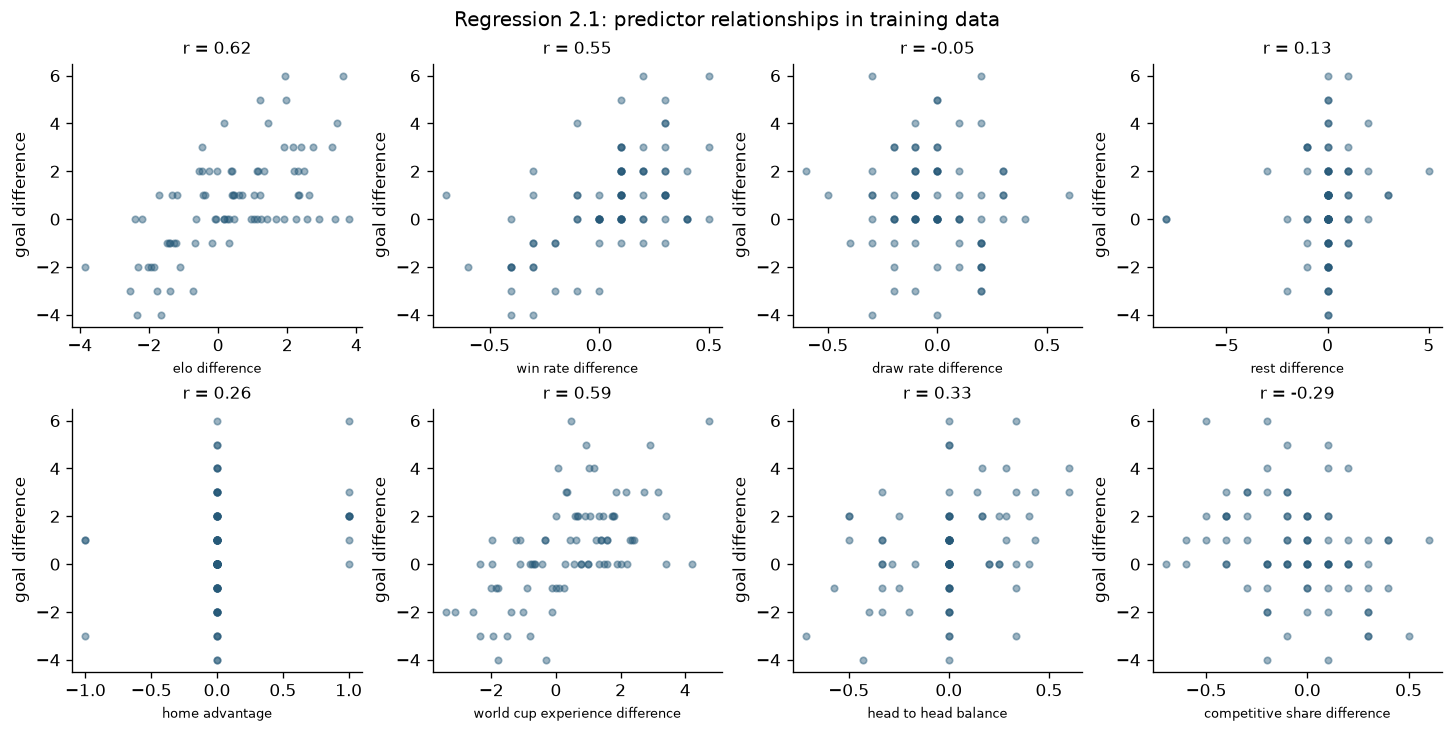

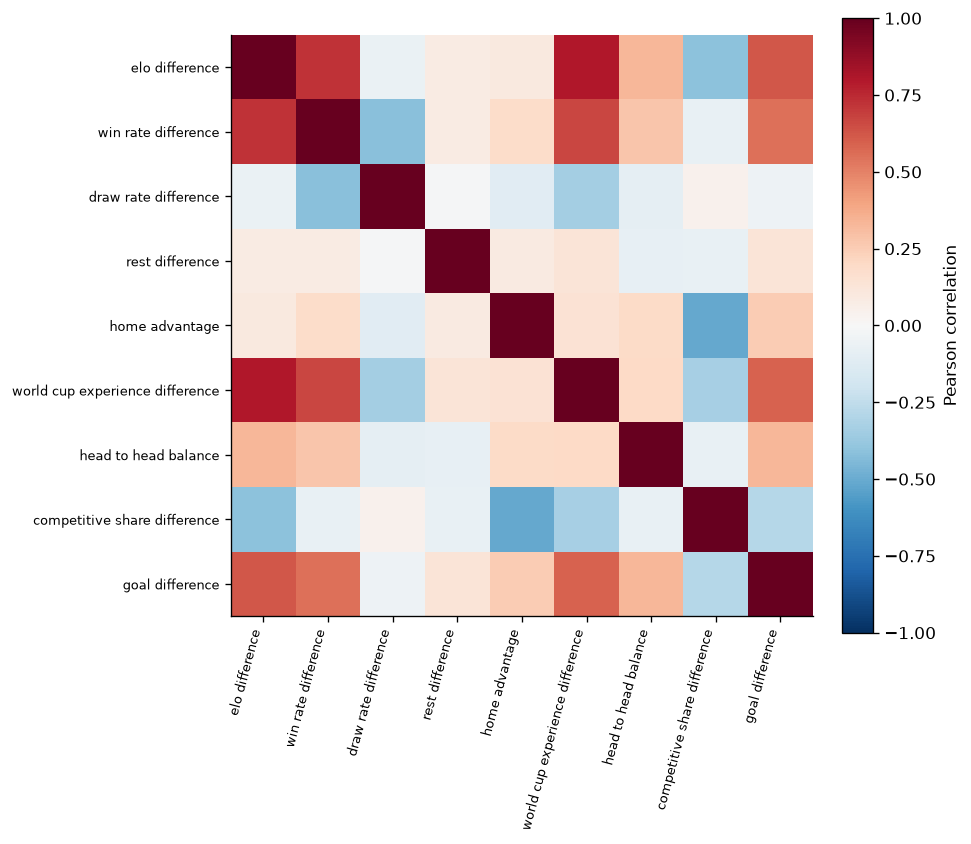

In [5]:
# Never use the final test set to select predictors or tune settings.
train[FEATURES + [TARGET]].describe().T.to_csv(OUT / "descriptive_training.csv")
correlation = train[FEATURES + [TARGET]].corr()
correlation.to_csv(OUT / "correlations_training.csv")
print("\nTraining correlations with the outcome:")
print(correlation[TARGET].drop(TARGET).round(3).sort_values())
fig, axes = plt.subplots(2, 4, figsize=(12, 6), layout="constrained")
for ax, feature in zip(axes.flat, FEATURES):
    ax.scatter(train[feature], y_train, alpha=0.45, s=15, color="#265978")
    ax.set(xlabel=feature.replace("_", " "), ylabel=TARGET.replace("_", " "))
    ax.xaxis.label.set_size(8)
    ax.set_title(f"r = {correlation.loc[feature, TARGET]:.2f}", fontsize=10)
fig.suptitle(f"Regression {MODEL}: predictor relationships in training data")
fig.savefig(OUT / "eda.png", dpi=170, bbox_inches="tight")
plt.show()
plt.close(fig)
fig, ax = plt.subplots(figsize=(8, 7), layout="constrained")
im = ax.imshow(correlation, vmin=-1, vmax=1, cmap="RdBu_r")
labels = [c.replace("_", " ") for c in correlation.columns]
ax.set_xticks(range(9), labels, rotation=75, ha="right", fontsize=8)
ax.set_yticks(range(9), labels, fontsize=8)
fig.colorbar(im, ax=ax, label="Pearson correlation")
fig.savefig(OUT / "correlations.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)




## 5. Compare methods with three expanding chronological folds

Compare ordinary least squares (OLS), ridge regression and random forests. The ridge scaler is fitted inside each training fold. Choose settings using validation MAE only. Mean and Elo-only predictions are reference baselines, not replacements for the required eight-predictor models.

In [6]:
# These alternatives supplement the required eight-predictor linear regression.
def new_model(method, setting):
    if method == "OLS":
        return LinearRegression()
    if method == "Ridge":
        return make_pipeline(StandardScaler(), Ridge(alpha=float(setting)))
    depth, leaf = setting.split(":")
    return RandomForestRegressor(
        n_estimators=200,
        max_depth=None if depth == "None" else int(depth),
        min_samples_leaf=int(leaf),
        random_state=42,
        n_jobs=1,
    )


def scores(actual, prediction):
    return {
        "MAE": float(mean_absolute_error(actual, prediction)),
        "RMSE": float(np.sqrt(mean_squared_error(actual, prediction))),
        "R2": float(r2_score(actual, prediction)),
    }


candidates = [("OLS", "default")] + [("Ridge", str(a)) for a in [0.1, 1, 10]]
candidates += [
    ("Random forest", f"{depth}:{leaf}") for depth in [3, "None"] for leaf in [3, 6]
]
dates = sorted(train.date.unique())
boundaries = [int(len(dates) * p) for p in [0.50, 0.65, 0.80]] + [len(dates)]
cv_rows = []
for fold, (begin, end) in enumerate(zip(boundaries[:-1], boundaries[1:]), start=1):
    tr = train[train.date.isin(dates[:begin])]
    va = train[train.date.isin(dates[begin:end])]
    assert tr.date.max() < va.date.min()
    assert set(tr.match_id).isdisjoint(va.match_id)
    for method, setting in candidates + [
        ("Mean baseline", "default"),
        ("Elo only", "default"),
    ]:
        if method == "Mean baseline":
            prediction = np.repeat(tr[TARGET].mean(), len(va))
        else:
            cols = ["elo_difference"] if method == "Elo only" else FEATURES
            estimator = (
                LinearRegression()
                if method == "Elo only"
                else new_model(method, setting)
            )
            estimator.fit(tr[cols], tr[TARGET])
            prediction = estimator.predict(va[cols])
        cv_rows.append(
            {
                "method": method,
                "setting": setting,
                "fold": fold,
                "train_matches": tr.match_id.nunique(),
                "validation_matches": va.match_id.nunique(),
                "validation_rows": len(va),
                "train_end": str(tr.date.max().date()),
                "validation_start": str(va.date.min().date()),
                "validation_end": str(va.date.max().date()),
                **scores(va[TARGET], prediction),
            }
        )
cv = pd.DataFrame(cv_rows)
cv.to_csv(OUT / "cross_validation.csv", index=False)
# Weight folds by validation rows: each validation observation has equal weight.
cv["absolute_error_sum"] = cv.MAE * cv.validation_rows
ranking = cv.groupby(["method", "setting"], as_index=False).agg(
    absolute_error_sum=("absolute_error_sum", "sum"), rows=("validation_rows", "sum")
)
ranking["CV_MAE"] = ranking.absolute_error_sum / ranking.rows
ranking = ranking.sort_values(["CV_MAE", "method", "setting"])
ranking.to_csv(OUT / "candidate_ranking.csv", index=False)
selected = ranking.groupby("method", sort=False).head(1)
print("\nBest settings for each method, selected using training folds only:")
print(selected[["method", "setting", "CV_MAE"]].to_string(index=False))




Best settings for each method, selected using training folds only:
       method setting   CV_MAE
     Elo only default 1.150299
        Ridge      10 1.155247
Random forest     3:3 1.159074
          OLS default 1.175027
Mean baseline default 1.616546


## 6. Fit the final models and evaluate on later matches

Fit on all training rows and compare unrounded predictions with actual later outcomes. MAE and RMSE measure errors in goals. Test R² can be negative. The coefficients are fixed throughout testing, although prior-match features update as results become available.

In [7]:
# Coefficients remain fixed. Features can update after an earlier test match finishes.
metric_rows = []
prediction_table = test[[row_id, "date", "team", "opponent", TARGET]].copy()
if row_id != "match_id":
    prediction_table.insert(1, "match_id", test.match_id)
for row in selected.itertuples():
    if row.method == "Mean baseline":
        prediction = np.repeat(y_train.mean(), len(test))
    else:
        cols = ["elo_difference"] if row.method == "Elo only" else FEATURES
        estimator = (
            LinearRegression()
            if row.method == "Elo only"
            else new_model(row.method, row.setting)
        )
        estimator.fit(train[cols], y_train)
        prediction = estimator.predict(test[cols])
    prediction_table[row.method] = prediction
    metric_rows.append(
        {
            "method": row.method,
            "setting": row.setting,
            "CV_MAE": row.CV_MAE,
            **scores(y_test, prediction),
        }
    )
metrics = pd.DataFrame(metric_rows)
metrics.to_csv(OUT / "metrics.csv", index=False)
prediction_table.to_csv(OUT / "predictions.csv", index=False)
print("\nLater-match evaluation (unrounded predictions):")
print(metrics.round(3).to_string(index=False))




Later-match evaluation (unrounded predictions):
       method setting  CV_MAE   MAE  RMSE     R2
     Elo only default   1.150 1.206 1.497  0.164
        Ridge      10   1.155 1.066 1.357  0.312
Random forest     3:3   1.159 1.042 1.389  0.280
          OLS default   1.175 1.051 1.317  0.353
Mean baseline default   1.617 1.466 1.768 -0.166


## 7. Explain OLS coefficients and check assumptions

Interpret coefficients while holding the other predictors constant. Use robust uncertainty and inspect residuals, predictor overlap and influential matches. A valid unusual score is not automatically a data error.

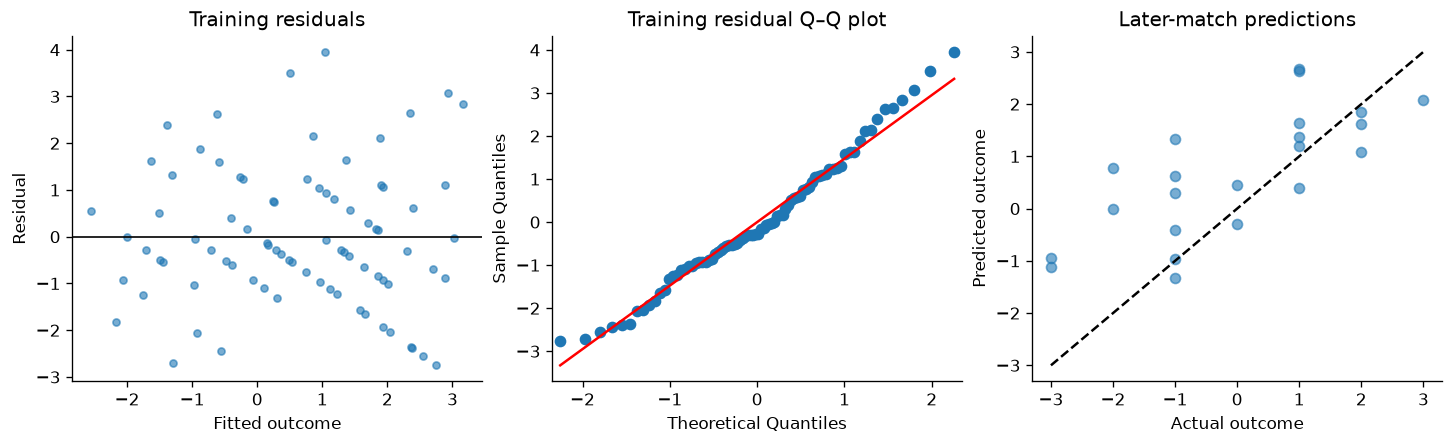

In [8]:
X_sm = sm.add_constant(X_train, has_constant="add")
assert np.linalg.matrix_rank(X_sm) == 9
fit = sm.OLS(y_train, X_sm).fit()
if MODEL == "2.1":
    robust = fit.get_robustcov_results(cov_type="HC3", use_t=True)
else:
    robust = fit.get_robustcov_results(
        cov_type="cluster",
        groups=train.match_id,
        use_correction=True,
        df_correction=True,
        use_t=True,
    )
interval = robust.conf_int()
coefficients = pd.DataFrame(
    {
        "variable": X_sm.columns,
        "coefficient": fit.params.to_numpy(),
        "SE": robust.bse,
        "lower95": interval[:, 0],
        "upper95": interval[:, 1],
        "p_value": robust.pvalues,
    }
)
coefficients.to_csv(OUT / "coefficients.csv", index=False)
assert np.allclose(
    fit.predict(sm.add_constant(X_test, has_constant="add")), prediction_table["OLS"]
)
vif = pd.DataFrame(
    {
        "variable": FEATURES,
        "VIF": [variance_inflation_factor(X_sm.to_numpy(), i) for i in range(1, 9)],
    }
)
vif.to_csv(OUT / "vif.csv", index=False)
influence = fit.get_influence()
cooks = influence.cooks_distance[0]
influence_table = train[["match_id", "team", TARGET]].copy()
influence_table["cooks_distance"] = cooks
influence_table.to_csv(OUT / "influence.csv", index=False)
most_influential = train.iloc[int(np.argmax(cooks))].match_id
reduced = train[train.match_id != most_influential]
sensitivity_model = LinearRegression().fit(reduced[FEATURES], reduced[TARGET])
sensitivity = scores(y_test, sensitivity_model.predict(X_test))
# This sensitivity never replaces the required primary fit.
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), layout="constrained")
axes[0].scatter(fit.fittedvalues, fit.resid, s=18, alpha=0.6)
axes[0].axhline(0, color="black", lw=1)
axes[0].set(xlabel="Fitted outcome", ylabel="Residual", title="Training residuals")
sm.qqplot(fit.resid, line="s", ax=axes[1])
axes[1].set_title("Training residual Q–Q plot")
axes[2].scatter(y_test, prediction_table["OLS"], alpha=0.6)
lo = min(y_test.min(), prediction_table.OLS.min())
hi = max(y_test.max(), prediction_table.OLS.max())
axes[2].plot([lo, hi], [lo, hi], "k--")
axes[2].set(
    xlabel="Actual outcome", ylabel="Predicted outcome", title="Later-match predictions"
)
fig.savefig(OUT / "diagnostics.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)



## 8. Quantify uncertainty and summarise

Resample complete test matches for approximate uncertainty. Repeated teams still create dependence across matches. These intervals condition on the fitted model and are not intervals for a single future score. The test results had already been inspected in earlier project drafts, so the added comparisons are exploratory rather than a new blind evaluation.

In [9]:
# Bootstrap whole matches so the paired team rows are never separated.
ids = test.match_id.unique()
indices = [np.flatnonzero(test.match_id.to_numpy() == match) for match in ids]
rng = np.random.default_rng(42)
y = y_test.to_numpy()
pred = prediction_table.OLS.to_numpy()
base = prediction_table["Mean baseline"].to_numpy()
boot = []
for _ in range(3000):
    ix = np.concatenate([indices[i] for i in rng.integers(0, len(ids), len(ids))])
    error = np.mean(abs(y[ix] - pred[ix]))
    boot.append([error, np.mean(abs(y[ix] - base[ix])) - error])
ci = np.quantile(boot, [0.025, 0.975], axis=0)
summary = {
    "model": MODEL,
    "train_matches": int(train.match_id.nunique()),
    "test_matches": int(test.match_id.nunique()),
    "train_rows": len(train),
    "test_rows": len(test),
    "cutoff": str(cutoff.date()),
    "training_R2": float(fit.rsquared),
    "training_adjusted_R2": float(fit.rsquared_adj),
    "max_VIF": float(vif.VIF.max()),
    "breusch_pagan_p": float(het_breuschpagan(fit.resid, X_sm)[1]),
    "shapiro_p": float(stats.shapiro(fit.resid).pvalue),
    "joint_F_p": float(robust.f_pvalue),
    "cooks_flagged": int((cooks > 4 / len(train)).sum()),
    "MAE_interval95": ci[:, 0].tolist(),
    "baseline_improvement_interval95": ci[:, 1].tolist(),
    "sensitivity_omitted_match": most_influential,
    "sensitivity_metrics": sensitivity,
    "negative_test_predictions": int((pred < 0).sum()),
    "recommended_by_CV": ranking.iloc[0]["method"],
    "coefficients": dict(zip(X_sm.columns, fit.params.to_numpy())),
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2))
(OUT / "ols_summary.txt").write_text(robust.summary().as_text())
print("\nOLS coefficients and 95% intervals:")
print(coefficients.round(3).to_string(index=False))
print("\nDiagnostics and uncertainty:")
print(json.dumps(summary, indent=2))
print(f"\nSaved results to {OUT}")
print(
    "Limitations: repeated teams, a small knockout-only test set, and variable match duration."
)
print(
    "Bootstrap intervals are approximate, conditional on this fitted model, not prediction intervals."
)
print(
    "These comparisons extend work whose test outcomes were already viewed; independent future validation is still needed."
)



OLS coefficients and 95% intervals:
                       variable  coefficient    SE  lower95  upper95  p_value
                          const        0.295 0.180   -0.064    0.655    0.106
                 elo_difference        0.008 0.289   -0.568    0.585    0.977
            win_rate_difference        2.613 1.692   -0.759    5.986    0.127
           draw_rate_difference        2.435 1.147    0.149    4.721    0.037
                rest_difference        0.077 0.126   -0.175    0.329    0.546
                 home_advantage        0.540 0.651   -0.759    1.838    0.410
world_cup_experience_difference        0.452 0.187    0.078    0.825    0.018
           head_to_head_balance        1.366 0.774   -0.178    2.909    0.082
   competitive_share_difference       -0.656 1.077   -2.803    1.490    0.544

Diagnostics and uncertainty:
{
  "model": "2.1",
  "train_matches": 82,
  "test_matches": 22,
  "train_rows": 82,
  "test_rows": 22,
  "cutoff": "2026-07-01",
  "training_R2": 0.4978

## How to use the results in the report

Explain the predictor choices, discuss training-only exploration, report OLS errors against baselines, interpret a few coefficients, and acknowledge limitations. Compare alternative methods using validation and test results separately. A smaller error for team goals does not by itself make that task easier than predicting a goal difference.

For full provenance, run `python Data/prepare_data.py` and `python Data/validate_data.py` from the repository root. These rebuild the features from archived source records and check dates, targets and file hashes.
